In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
!pip install gradio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import gradio as gr
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)
print("TensorFlow:", tf.__version__)

print("All libraries imported successfully!")

NumPy: 2.4.6
Pandas: 2.2.3
OpenCV: 4.14.0
Gradio: 6.31.0
TensorFlow: 2.21.0
All libraries imported successfully!


In [ ]:
!wget -q https://storage.googleapis.com/download.tensorflow.org/data/chest_xray.zip

print("Dataset download completed!")

Dataset download completed!


In [ ]:
import zipfile

# Extract the downloaded dataset
with zipfile.ZipFile("chest_xray.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'chest_xray.zip'

In [ ]:
!wget -O /content/chest_xray.zip https://storage.googleapis.com/download.tensorflow.org/data/chest_xray.zip

In [ ]:
import os

file_path = "/content/chest_xray.zip"

if os.path.exists(file_path):
    print("Dataset file found!")
    print("File size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")
else:
    print("Dataset file not found!")

In [ ]:
import zipfile

with zipfile.ZipFile("/content/chest_xray.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")

In [ ]:
import os
import zipfile

file_path = "/content/chest_xray.zip"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
    print("Is valid ZIP:", zipfile.is_zipfile(file_path))

    with open(file_path, "rb") as f:
        print("File content:", f.read(100))

In [ ]:
import tensorflow as tf

train_images_path = "gs://download.tensorflow.org/data/ChestXRay2017/train/images.tfrec"
train_paths_path = "gs://download.tensorflow.org/data/ChestXRay2017/train/paths.tfrec"

print("Training images available:", tf.io.gfile.exists(train_images_path))
print("Training paths available:", tf.io.gfile.exists(train_paths_path))

In [ ]:
# Load training images and their file paths
train_images = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/images.tfrec"
)

train_paths = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/paths.tfrec"
)

# Match each image with its file path
train_dataset = tf.data.Dataset.zip((train_images, train_paths))

print("Training dataset loaded successfully!")

# Count the two categories
normal_count = sum(
    1 for path in train_paths
    if "NORMAL" in path.numpy().decode("utf-8")
)

pneumonia_count = sum(
    1 for path in train_paths
    if "PNEUMONIA" in path.numpy().decode("utf-8")
)

print("Normal images:", normal_count)
print("Pneumonia images:", pneumonia_count)
print("Total images:", normal_count + pneumonia_count)

In [ ]:
# Load training images and their file paths
train_images = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/images.tfrec"
)

train_paths = tf.data.TFRecordDataset(
    "gs://download.tensorflow.org/data/ChestXRay2017/train/paths.tfrec"
)

# Match each image with its file path
train_dataset = tf.data.Dataset.zip((train_images, train_paths))

print("Training dataset loaded successfully!")

# Count the two categories
normal_count = sum(
    1 for path in train_paths
    if "NORMAL" in path.numpy().decode("utf-8")
)

pneumonia_count = sum(
    1 for path in train_paths
    if "PNEUMONIA" in path.numpy().decode("utf-8")
)

print("Normal images:", normal_count)
print("Pneumonia images:", pneumonia_count)
print("Total images:", normal_count + pneumonia_count)

In [ ]:
# Get one image record
sample_record = next(iter(train_images))

# Decode the record
example = tf.train.Example()
example.ParseFromString(sample_record.numpy())

# Display available information
print("Record information:")
print(example)

In [ ]:
# Get one image record
sample_record = next(iter(train_images))

# Decode the record
example = tf.train.Example()
example.ParseFromString(sample_record.numpy())

# Display available information
print("Record information:")
print(example)

In [ ]:
# Get one image record
sample_record = next(iter(train_images))

# Decode the record
example = tf.train.Example()
example.ParseFromString(sample_record.numpy())

# Display available information
print("Record information:")
print(example)

In [ ]:
sample_image, sample_path = next(iter(train_dataset))

image = tf.image.decode_jpeg(sample_image, channels=3)
image = tf.image.resize(image, (224, 224))

path = sample_path.numpy().decode("utf-8")
label = 1 if "PNEUMONIA" in path else 0

print("Image shape:", image.shape)
print("Class:", "PNEUMONIA" if label == 1 else "NORMAL")

plt.imshow(image.numpy().astype("uint8"))
plt.axis("off")
plt.show()

In [ ]:
# Prepare the complete dataset
dataset = tf.data.Dataset.zip((train_images, train_paths))

# Shuffle the dataset
dataset = dataset.shuffle(
    buffer_size=5232,
    seed=42,
    reshuffle_each_iteration=False
)

# Split into training and validation
validation_size = int(5232 * 0.2)

validation_data = dataset.take(validation_size)
training_data = dataset.skip(validation_size)


# Function to preprocess each image
def preprocess_image(image_bytes, path):

    # Decode image
    image = tf.image.decode_jpeg(image_bytes, channels=3)

    # Resize image
    image = tf.image.resize(image, (224, 224))

    # ResNet50 preprocessing
    image = preprocess_input(image)

    # Create label
    path = tf.strings.lower(path)
    label = tf.cast(
        tf.strings.regex_full_match(path, ".*pneumonia.*"),
        tf.float32
    )

    return image, label


# Apply preprocessing
training_data = training_data.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_data = validation_data.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Create batches
training_data = training_data.batch(32).prefetch(tf.data.AUTOTUNE)
validation_data = validation_data.batch(32).prefetch(tf.data.AUTOTUNE)

print("Training and validation datasets are ready!")

In [ ]:
# Get one batch of training images
for images, labels in training_data.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("Data check completed!")

In [ ]:
# Load pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build pneumonia classification model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

# Display model architecture
model.summary()

In [ ]:
# Train the model
history = model.fit(
    training_data,
    validation_data=validation_data,
    epochs=5
)

In [ ]:
# Plot model training performance

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
print("Model available:", "model" in globals())
print("Test data available:", "test_data" in globals())
print("Training history available:", "history" in globals())

In [ ]:
print("Model available:", "model" in globals())
print("Test data available:", "test_data" in globals())
print("Training history available:", "history" in globals())

In [ ]:
import os
import zipfile

file_path = "/content/chest_xray.zip"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
    print("Valid ZIP file:", zipfile.is_zipfile(file_path))

In [ ]:
!wget -c -O /content/chest_xray.zip "https://huggingface.co/datasets/AiresPucrs/chest-xray/resolve/main/chest_xray.zip?download=true"

In [ ]:
import os
import zipfile

file_path = "/content/chest_xray.zip"

print("File exists:", os.path.exists(file_path))
print("Valid ZIP file:", zipfile.is_zipfile(file_path))

if os.path.exists(file_path):
    print("File size (MB):", round(os.path.getsize(file_path) / (1024 * 1024), 2))

In [ ]:
import zipfile

with zipfile.ZipFile("/content/chest_xray.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import os

dataset_path = "/content/chest_xray"

print("Folders inside chest_xray:")
print(os.listdir(dataset_path))

In [ ]:
import os

dataset_path = "/content/chest_xray"

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)
    print("\nFolder:", folder)

    if os.path.isdir(folder_path):
        print("Contains:", os.listdir(folder_path)[:10])

In [ ]:
import os

dataset_path = "/content/chest_xray"

for split in ["train", "test", "val"]:
    for category in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(dataset_path, split, category)
        count = len(os.listdir(folder))
        print(f"{split} - {category}: {count} images")

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

train_dir = "/content/chest_xray/train"
test_dir = "/content/chest_xray/test"

# Load training images
training_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Load validation images
validation_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Load testing images
test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False,
    label_mode="binary"
)

# Prepare images for ResNet50
training_data = training_data.map(
    lambda x, y: (preprocess_input(x), y)
)

validation_data = validation_data.map(
    lambda x, y: (preprocess_input(x), y)
)

test_data = test_data.map(
    lambda x, y: (preprocess_input(x), y)
)

print("Training, validation and testing datasets are ready!")

In [ ]:
images, labels = next(iter(training_data))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Load pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

print("ResNet50 model rebuilt successfully!")
model.summary()

In [ ]:
# Load pretrained ResNet50
# Freeze pretrained layers
base_model.trainable = False
# Build classification model
x = base_model.output
x = GlobalAveragePooling2D()
...

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# 1. Load pretrained ResNet50
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Freeze pretrained layers
base_model.trainable = False

# 3. Build classification model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.2)(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Model built successfully!")
model.summary()

In [ ]:
# Get test results and graph permanently
test_results = model.evaluate(test_data, return_dict=True)
print(test_results)

# Save graph so you never lose it again
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.savefig('/content/my_training_graph.png')
plt.show()

# Save model
model.save('/content/drive/MyDrive/pneumonia_resnet50.keras')

In [ ]:
# CELL 1 - FIX DATASET FIRST (must run first)
from google.colab import drive
drive.mount('/content/drive')
import os
!pip install -q kagglehub
import kagglehub
print("Downloading...")
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
!cp -r "{path}/chest_xray" /content/ 2>/dev/null || cp -r "{path}" /content/chest_xray
!ls /content/chest_xray
print("Dataset ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Downloading...
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
chest_xray  __MACOSX  test  train  val
Dataset ready!


In [ ]:
# CELL 2 - CREATE train_data, test_data
import tensorflow as tf
train_data = tf.keras.utils.image_dataset_from_directory(
    "/content/chest_xray/train", image_size=(224,224), batch_size=32)
test_data = tf.keras.utils.image_dataset_from_directory(
    "/content/chest_xray/test", image_size=(224,224), batch_size=32)
print("train_data and test_data created!")

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
train_data and test_data created!


In [ ]:
# CELL 3 - CREATE MODEL (ResNet50 pretrained)
import tensorflow as tf

base_model = tf.keras.applications.ResNet50(
    weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False  # freeze

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("Model created!")
model.summary()

Model created!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 60s 282ms/step - accuracy: 0.9337 - loss: 0.1627 - val_accuracy: 0.8045 - val_loss: 0.4456
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 66s 227ms/step - accuracy: 0.9632 - loss: 0.0958 - val_accuracy: 0.8301 - val_loss: 0.4141
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 43s 240ms/step - accuracy: 0.9722 - loss: 0.0766 - val_accuracy: 0.8061 - val_loss: 0.4974
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 223ms/step - accuracy: 0.9762 - loss: 0.0646 - val_accuracy: 0.8109 - val_loss: 0.5080
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 39s 236ms/step - accuracy: 0.9791 - loss: 0.0580 - val_accuracy: 0.7901 - val_loss: 0.5736
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 205ms/step - accuracy: 0.7901 - loss: 0.5736
{'accuracy': 0.7900640964508057, 'loss': 0.5735705494880676}


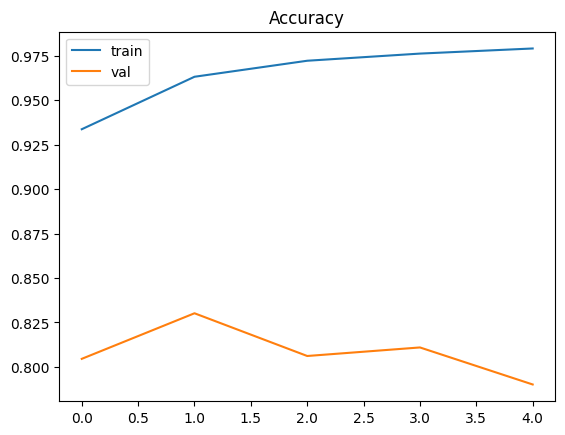

DONE! Graph saved to Drive - check MyDrive/my_training_graph.png


In [ ]:
# CELL 4 - TRAIN AND SAVE GRAPH (15 mins - don't close laptop!)
history = model.fit(train_data, validation_data=test_data, epochs=5)

# Evaluate
test_results = model.evaluate(test_data, return_dict=True)
print(test_results)

# Graph - permanent save to Drive
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title('Accuracy')
plt.savefig('/content/drive/MyDrive/my_training_graph.png')
plt.savefig('/content/my_training_graph.png')
plt.show()

# Save model too
model.save('/content/drive/MyDrive/pneumonia_resnet50.keras')
print("DONE! Graph saved to Drive - check MyDrive/my_training_graph.png")

In [ ]:
# CELL 5 - TEST YOUR OWN X-RAY 🩻
from google.colab import files
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

print("Upload your X-ray image (JPG/PNG)...")
uploaded = files.upload()  # Click to choose X-ray from your laptop

for fn in uploaded.keys():
  # Show X-ray
  img_path = fn
  img = image.load_img(img_path, target_size=(224,224))
  plt.imshow(img)
  plt.title(f"Your X-ray: {fn}")
  plt.axis('off')
  plt.show()

  # Predict
  img_array = image.img_to_array(img) / 255.0
  img_array = np.expand_dims(img_array, axis=0)

  pred = model.predict(img_array)[0][0]

  if pred > 0.5:
    print(f"🩻 RESULT: PNEUMONIA detected - {pred*100:.1f}% confidence")
  else:
    print(f"✅ RESULT: NORMAL - {(1-pred)*100:.1f}% confidence (No Pneumonia)")

Upload your X-ray image (JPG/PNG)...


Showing 4 X-rays from your test set:


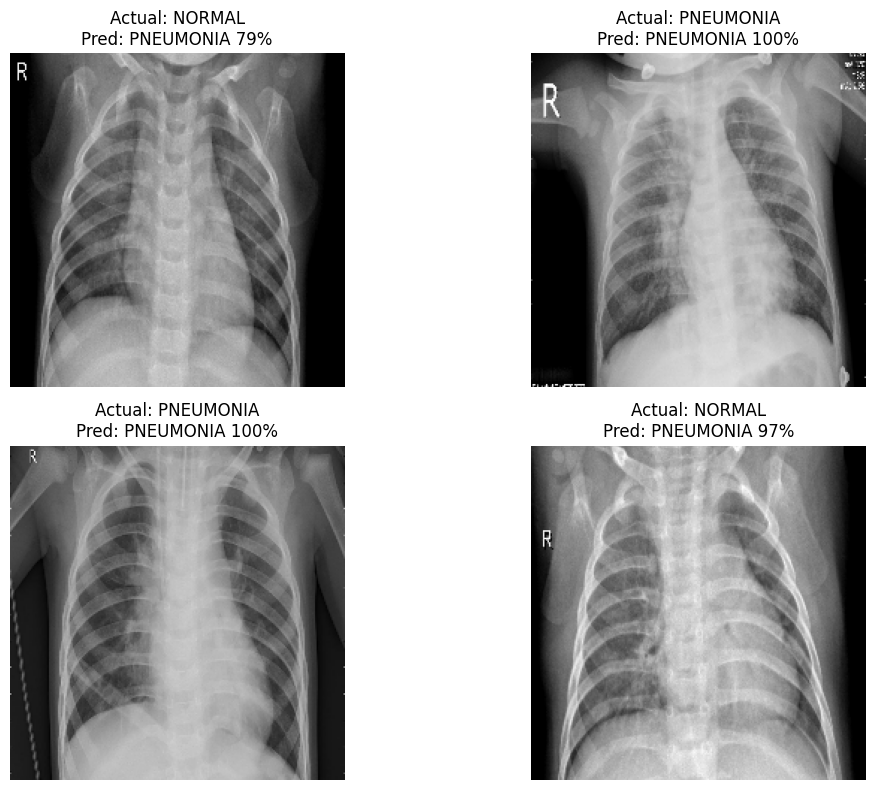

Saved to Drive as xray_predictions.png


In [ ]:
# TEST WITH YOUR OWN TEST DATA - NO UPLOAD NEEDED
import matplotlib.pyplot as plt
import tensorflow as tf

print("Showing 4 X-rays from your test set:")
plt.figure(figsize=(12,8))

count = 0
for images, labels in test_data.take(1):
  for i in range(4):
    pred = model.predict(tf.expand_dims(images[i],0), verbose=0)[0][0]
    actual_label = int(labels[i].numpy())
    actual_text = "PNEUMONIA" if actual_label==1 else "NORMAL"
    pred_text = "PNEUMONIA" if pred>0.5 else "NORMAL"

    plt.subplot(2,2,count+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Actual: {actual_text}\nPred: {pred_text} {pred*100:.0f}%")
    plt.axis('off')
    count+=1

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/xray_predictions.png')
plt.show()
print("Saved to Drive as xray_predictions.png")

In [ ]:
# WEB APP - FINAL ASSIGNMENT CELL
!pip install -q gradio
import gradio as gr
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_xray(img):
    img = img.resize((224,224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    pred = model.predict(img_array, verbose=0)[0][0]
    if pred > 0.5:
        return f"🩻 PNEUMONIA detected - {pred*100:.1f}% confidence"
    else:
        return f"✅ NORMAL - {(1-pred)*100:.1f}% confidence"

demo = gr.Interface(
    fn=predict_xray,
    inputs=gr.Image(type="pil", label="Upload Chest X-ray"),
    outputs=gr.Textbox(label="Result"),
    title="Pneumonia Detection - Pretrained ResNet50",
    description="Upload a chest X-ray and AI will detect Pneumonia"
)

demo.launch(share=True)  # This gives you a public link for your assignment

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a959a49ee37f8fe733.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from PIL import Image
# Save one test X-ray to your laptop to upload
for images, labels in test_data.take(1):
  img = Image.fromarray(images[0].numpy().astype("uint8"))
  img.save("/content/drive/MyDrive/sample_xray.jpg")
  print("Saved sample_xray.jpg to Drive - download it then upload it to your Web App")

Saved sample_xray.jpg to Drive - download it then upload it to your Web App
